# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: CapeFlats
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 24)
Train: 785 | Val: 192 | Test: 766


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 3.42e-04 | train loss 1.1070 acc 0.460 | val loss 1.0283 acc 0.458 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 3.42e-04 | train loss 1.0422 acc 0.515 | val loss 0.8907 acc 0.661 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 3.42e-04 | train loss 1.0441 acc 0.552 | val loss 1.0250 acc 0.651


[ResNet-18 (scratch)] Epoch   4/100 | LR: 3.42e-04 | train loss 1.0319 acc 0.630 | val loss 0.9924 acc 0.661


...

[ResNet-18 (scratch)] Epoch  19/100 | LR: 3.42e-04 | train loss 1.0021 acc 0.592 | val loss 0.8330 acc 0.693


[ResNet-18 (scratch)] Epoch  20/100 | LR: 3.42e-04 | train loss 0.9664 acc 0.603 | val loss 0.9339 acc 0.688


[ResNet-18 (scratch)] Epoch  21/100 | LR: 3.42e-04 | train loss 0.9624 acc 0.645 | val loss 0.8782 acc 0.635


[ResNet-18 (scratch)] Epoch  22/100 | LR: 3.42e-04 | train loss 0.9692 acc 0.625 | val loss 0.8787 acc 0.620


[ResNet-18 (scratch)] Epoch  23/100 | LR: 3.42e-04 | train loss 0.9720 acc 0.550 | val loss 1.0499 acc 0.635

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 23.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.8208)


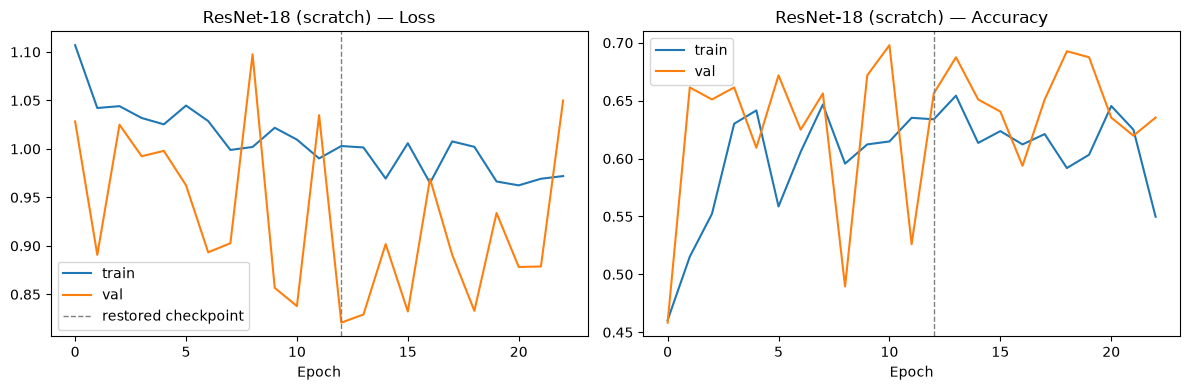

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.209


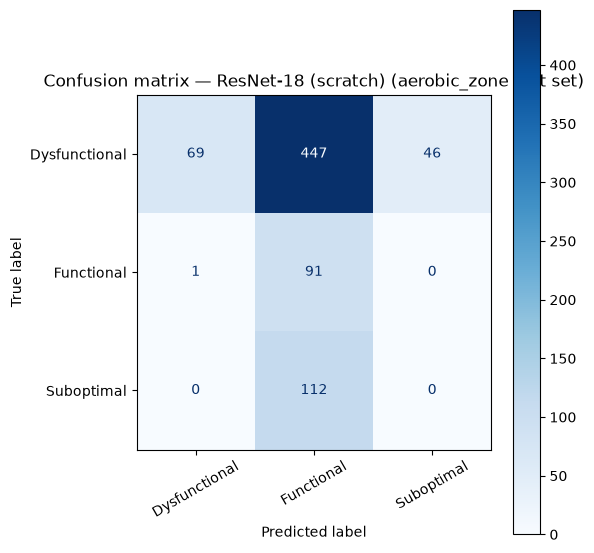

               precision    recall  f1-score   support

Dysfunctional      0.986     0.123     0.218       562
   Functional      0.140     0.989     0.245        92
   Suboptimal      0.000     0.000     0.000       112

     accuracy                          0.209       766
    macro avg      0.375     0.371     0.155       766
 weighted avg      0.740     0.209     0.190       766



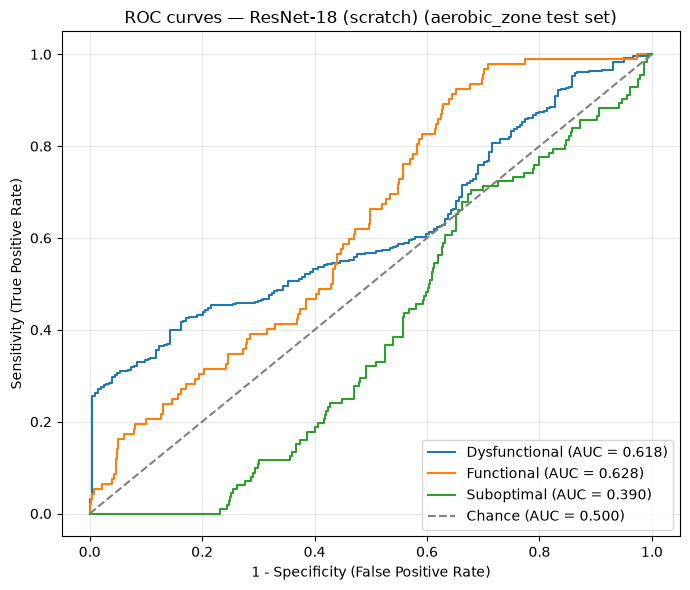

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.618
  Functional     : 0.628
  Suboptimal     : 0.390

Mean AUC (over 3/3 classes with test examples): 0.545


(np.float64(0.20887728459530025),
 {'Dysfunctional': 0.6175336682715791,
  'Functional': 0.6283544058831119,
  'Suboptimal': 0.39046799912625596})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_CapeFlats.pkl
Saved model weights to ../models/pad/aerobic_zone_aug/aerobic_zone_resnet18_scratch_CapeFlats.pt
